<a href="https://colab.research.google.com/github/doubletran/GOES_water_vapor/blob/main/MCC_2020__A_Mesoscale_Convective_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MCC 2020: A Mesoscale Convective System (animation)

* **Projection**: equidistant cylindrical (equirectangular) Plate Carrée projection.  
  Plate Carrée is a cylindrical projection. The meridians and parallels are equally spaced straight lines forming a Cartesian grid of perfect squares in the normal aspect. In this projection, the poles are represented as straight lines across the top and bottom of the grid, the same length as equator. The graticule is symmetrical across the equator and the central meridian.
* **Dataset**: GOES-R
  The data are provided in the original spatial resolution of the infrared channels (2 km) on a geostationary grid every 10 minutes.
* **Event**: A Mesoscale Convective System 2020-11-14.

## Parameters

Adjust these values for each event you wish to analise, they change often:

In [27]:
# Set the name of the event
EVENT = "AUGUST_TPW"

# Set the time window of the event
# Note: leave the end time empty to study a single instant, it
#     must be in the format specified in the constant
#     DATE_FORMAT_IN; see the configuration section below.
TIME_START = "2020-08-16T17:00Z"
TIME_END = "2020-08-16T22:00Z"

# Set the satellite (origin) identifier
# Note: it must be a string (e.g. "G16").
# Available origins:
#     "G16" to "G19": GOES 4th generation (R to U) series,
ORIGINS = "G17"

# Set the band identifier
# Note: Channel 13 - TOA Brightness Temperature - 10.3 μm for this example.
#     it can be a string (e.g. "C08") or a sequence of strings (e.g.
#     ["G07", "G15"]).
CHANNEL = "C08"

# Set the scene identifier
# Available scenes:
#     "F": "Full Disk",
#     "C": "CONUS (Contiguous United States)".
#    "Mn": "Mesoscale", n = 1 or 2.
SCENE = "F"

# Set the central longitude and latitude for the region of interest (ROI)
LON_CEN = -119.4 # for PY: -58.50
LAT_CEN = 36.77 # for PY: -23.50

# Set the extent of the ROI (longitude and latitude field of view in degrees)
ROI_EXTENT = (11, 11)

## Configuration

Adjust these values to fulfill your needs and requirements; they do not change very often:

In [28]:
from pathlib import Path

# Set the path of the datasets repository
REPOSITORY_ROOT = Path("./data")
REPOSITORY_PATH = REPOSITORY_ROOT / EVENT
REPOSITORY_PATH.mkdir(parents=True, exist_ok=True)

# Set the path of the media repository
MEDIA_ROOT = Path("./media")
MEDIA_PATH = MEDIA_ROOT / EVENT
MEDIA_PATH.mkdir(parents=True, exist_ok=True)

# Set the media suffix (extension) for the generated images
# Note: this define the output file format.
MEDIA_SUFFIX = ".png"

# Set the media suffix for the generated animation
# Note: this define the output file format.
# Supported animation formats:
#     ".gif": Animated GIF, up to 256 colours palette,
#     ".png": Animated PNG, support true colours,
#     ".webp": Animated WebP, support true colours.
ANIMATION_SUFFIX = ".gif"

# Miscellaneous constants
DATE_FORMAT_DT = "%Y/%m/%d %H:%M:%S%:z"
DATE_FORMAT_IN = "%Y-%m-%dT%H:%M%z"
DATE_FORMAT_FG = "%Y/%m/%d %H:%M %Z"
ROI_CENTRE = (LON_CEN, LAT_CEN)

### Install requirements

Install or update **GOES-DL**:

In [3]:
from importlib import metadata, util

if util.find_spec("goesdl") is None:
    !pip install goes-dl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 36.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 54.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 55.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 51.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [goes-dl]


## Geodetic references

Configure here the target projection and the reference ellipsoid:

In [21]:
from cartopy import crs as ccrs

# Create the target (plotting) projection

target_globe = ccrs.Globe(ellipse="WGS84")

target_crs = ccrs.PlateCarree(
    central_longitude=0.0,
    globe=target_globe,
)

## Download the required datasets

In [29]:
# Import the locator, datasource and downloader
from goesdl.goesr import GOESProductLocatorABIDP
from goesdl.datasource import DatasourceAWS
from goesdl.downloader import Downloader

# Initialize the product locator for GridSat-GOES
#
# Available scenes:
#     "F": "Full Disk",
#     "C": "CONUS (Contiguous United States)".
#
# Available origins:
#     "G08" to "G12": GOES 2nd generation (I to M) series,
#     "G13" to "G15": GOES 3rd generation (N to P) series.
#
# Note: The `origin` parameter can take a list of origins
#       as argument, e.g. origins=["G11", "G12"].
locator = GOESProductLocatorABIDP(name='TPW',scene=SCENE,origin=ORIGINS)

# GOES-R database is available from NOAA's AWS archive
datasource = DatasourceAWS(locator)

# Initialize the downloader with the locator and datasource
downloader = Downloader(
    datasource=datasource,
    locator=locator,
    repository=REPOSITORY_PATH,
    date_format=DATE_FORMAT_IN,
)

# --- Optional: Show both times for comparison ---
print(f"Coverage UTC start time : {TIME_START}")
print(f"Coverage UTC end time   : {TIME_END or TIME_START}\n")

# Download the datasets within a given date range
#
# Note: To download for a specific date and time you might do
#       `downloader.download_files(start="2012-08-23T00:00Z")`.
files = downloader.download_files(
    start=TIME_START,
    end=TIME_END,
)

if not files:
    print("Unable to acquire files: no file found in the specified range\n")
else:
    print(f"Successfully acquired {len(files)} files")

# Note: The returned list of file paths are relative to the
#     repository root, to match the absolute path in the
#     datasource file syste, so, we need to reconstruct
#     the dataset paths to access our local copy.
dataset_paths = [REPOSITORY_PATH / file for file in files]

Coverage UTC start time : 2020-08-16T17:00Z
Coverage UTC end time   : 2020-08-16T22:00Z

Retrieving available file list
 1/31 2020/229/17/OR_ABI-L2-TPWF-M6_G17_s20202291700321_e20202291709387_c20202291710176.nc
      ... downloaded succesfully
 2/31 2020/229/17/OR_ABI-L2-TPWF-M6_G17_s20202291710321_e20202291719387_c20202291720248.nc
      ... downloaded succesfully
 3/31 2020/229/17/OR_ABI-L2-TPWF-M6_G17_s20202291720321_e20202291729388_c20202291730179.nc
      ... downloaded succesfully
 4/31 2020/229/17/OR_ABI-L2-TPWF-M6_G17_s20202291730321_e20202291739387_c20202291740213.nc
      ... downloaded succesfully
 5/31 2020/229/17/OR_ABI-L2-TPWF-M6_G17_s20202291740321_e20202291749388_c20202291750245.nc
      ... downloaded succesfully
 6/31 2020/229/17/OR_ABI-L2-TPWF-M6_G17_s20202291750321_e20202291759388_c20202291800219.nc
      ... downloaded succesfully
 7/31 2020/229/18/OR_ABI-L2-TPWF-M6_G17_s20202291800321_e20202291809388_c20202291810245.nc
      ... downloaded succesfully
 8/31 2020/2

## Calculate the limits for the plot and data extraction

In [24]:
from goesdl.geodesy import RectangularRegion

# Calculate the data domain and the plot limits
region = RectangularRegion.from_central_point(ROI_EXTENT, ROI_CENTRE)

## Extract the relevant data from the dataset

In [69]:
import numpy as np
from netCDF4 import Dataset
from goesdl.goesr import GOESLatLonGrid, GOESImage, GOESDatasetInfo

data_seq = []
metadata_seq = []

if isinstance(ORIGINS, str):
    ORIGINS = [ORIGINS]
mini, maxi =100, 0
# Set the path and file name of the dataset and extract required data
for i, dataset_path in enumerate(dataset_paths):
    with Dataset(dataset_path, "r") as dataframe:

        # Get all required data by entity in separate calls: lat. and
        # lon. grids, image data, coverage time*, metadata*).
        # *) These data are not required to plot the image, they are
        #    jus used to extract information for labeling the image.
        grid = GOESLatLonGrid(dataframe, region)  #, corners=True

        data = GOESImage(dataframe, grid)
        data_seq.append(data)
        mini = np.minimum(mini, np.nanmin(data.image))
        maxi = np.maximum(maxi, np.nanmax(data.image))

        metadata = GOESDatasetInfo(dataframe, CHANNEL)
        metadata_seq.append(metadata)

    print(f"\nDataset {i + 1}/{len(dataset_paths)}")
    print("-----------------------------------------------------")
    print(f"Record:    {metadata.dataset_name}")
    print("-----------------------------------------------------")
    print(f"Database                  : {metadata.database_name}")
    print(f"Time coverage start       : {metadata.coverage_start:{DATE_FORMAT_DT}}")
    print(f"Time coverage end         : {metadata.coverage_end:{DATE_FORMAT_DT}}")
    print(f"Platform                  : {metadata.plaform_name}")
    print(f"Measurement               : {metadata.measurement_name}")
    print(f"Band                      : Band {metadata.band_id} — {metadata.band_wavelength:.1f} μm")
    print(f"Minimum value             : {np.nanmin(data.image):.2f} [{metadata.units}]")
    print(f"Maximum value             : {np.nanmax(data.image):.2f} [{metadata.units}]")
    print(f"ROI shape (rows×columns)  : {data.image.shape[0]}×{data.image.shape[1]} px")
    print("-----------------------------------------------------\n")


Dataset 1/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291700321_e20202291709387_c20202291710176.nc
-----------------------------------------------------
Database                  : GOES
Time coverage start       : 2020/08/16 17:00:32+00:00
Time coverage end         : 2020/08/16 17:09:38+00:00
Platform                  : GOES-17
Measurement               : ABI L2+ Total Precipitable Water
Band                      : Band -999 — nan μm
Minimum value             : 5.07 [mm]
Maximum value             : 52.19 [mm]
ROI shape (rows×columns)  : 88×111 px
-----------------------------------------------------


Dataset 2/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291710321_e20202291719387_c20202291720248.nc
-----------------------------------------------------
Database                  : GOES
Time coverage start       : 2020/08/16 17:10:32+00:00
Time coverage end         : 2020/08/16 17:19:3

## Define and preview a false color enhancement scale

Here you can configure the enhancement scale:

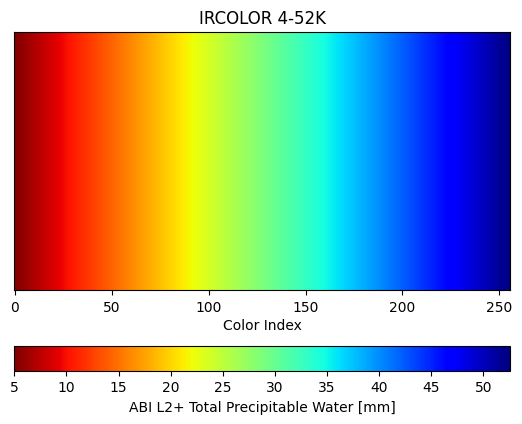

In [72]:
from goesdl.enhancement import EnhancementScale, show_colormap, cmap
key_points = (mini, maxi)  # (180, 240, 330)
color_maps = ("jet_r")
cmap_name = f"IRCOLOR {int(key_points[0])}-{int(key_points[1])}K"

# Get a stock palette and configure the ticks for the colorbar, for this example
enhancement = cmap['IRCOLOR']
enhancement = EnhancementScale.from_colormap(cmap_name, color_maps, key_points)
# Create a preview of the color map
measurement = f"{metadata.measurement_name} [{metadata.units}]"

show_colormap(enhancement, measurement)  #, offset=-269.4

In [71]:
min

65535

## Plot the region of interest


Dataset 1/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291700321_e20202291709387_c20202291710176.nc
-----------------------------------------------------


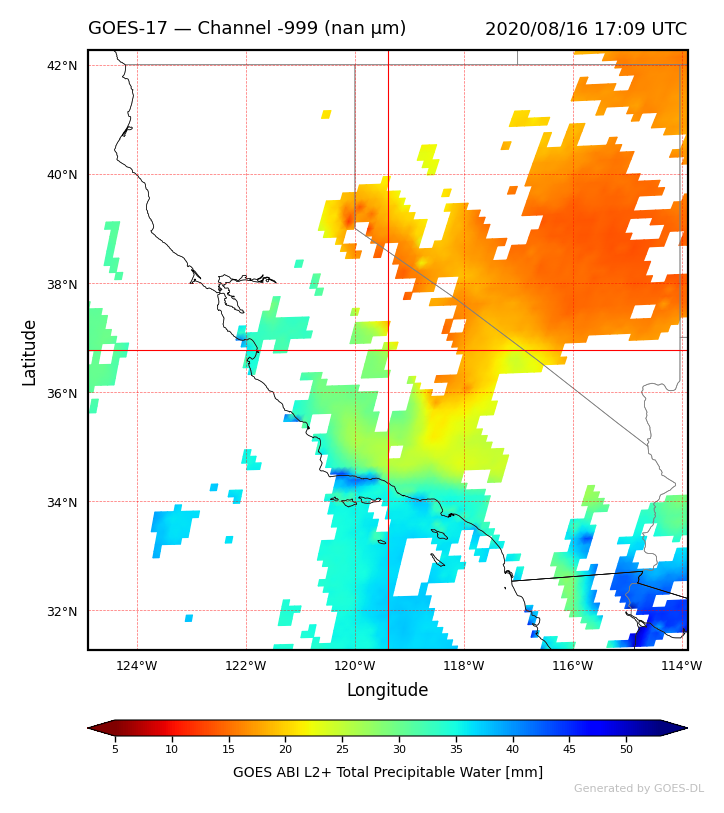


Dataset 2/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291710321_e20202291719387_c20202291720248.nc
-----------------------------------------------------


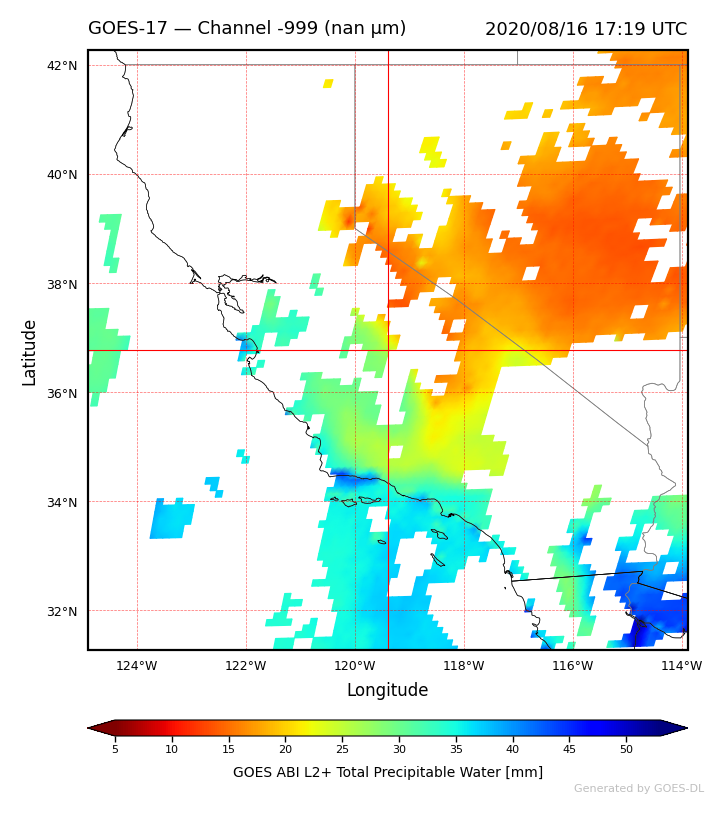


Dataset 3/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291720321_e20202291729388_c20202291730179.nc
-----------------------------------------------------


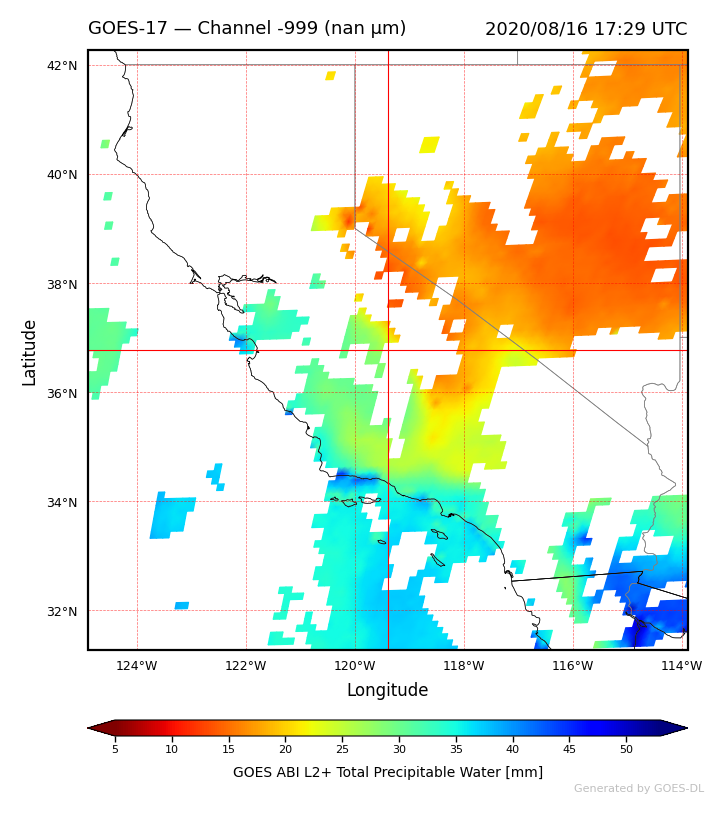


Dataset 4/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291730321_e20202291739387_c20202291740213.nc
-----------------------------------------------------


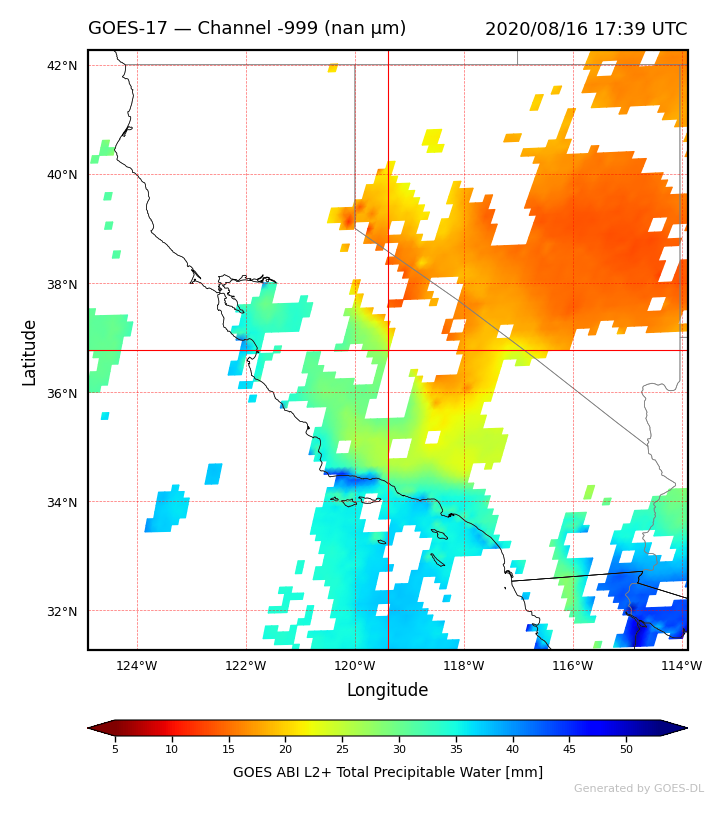


Dataset 5/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291740321_e20202291749388_c20202291750245.nc
-----------------------------------------------------


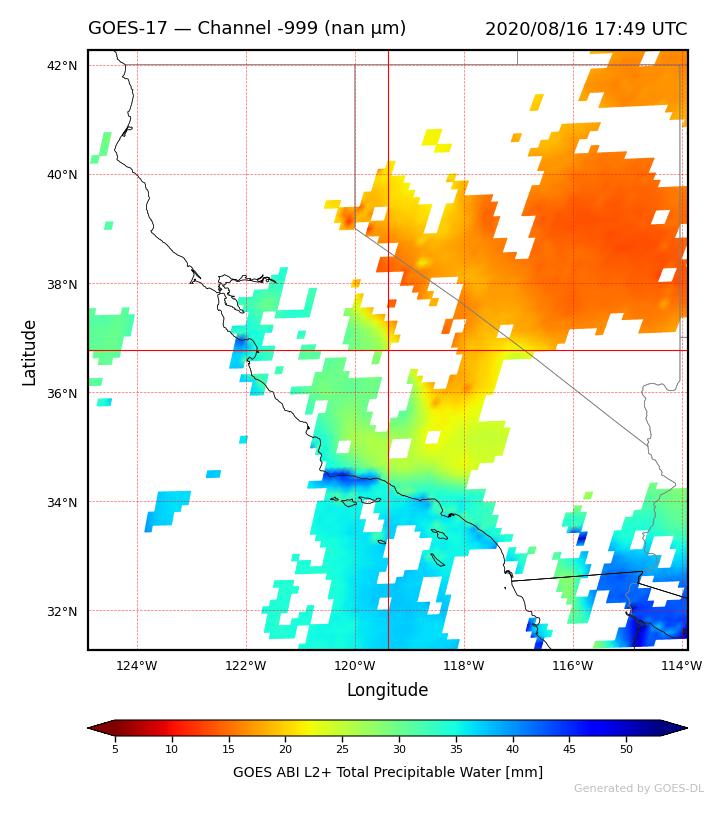


Dataset 6/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291750321_e20202291759388_c20202291800219.nc
-----------------------------------------------------


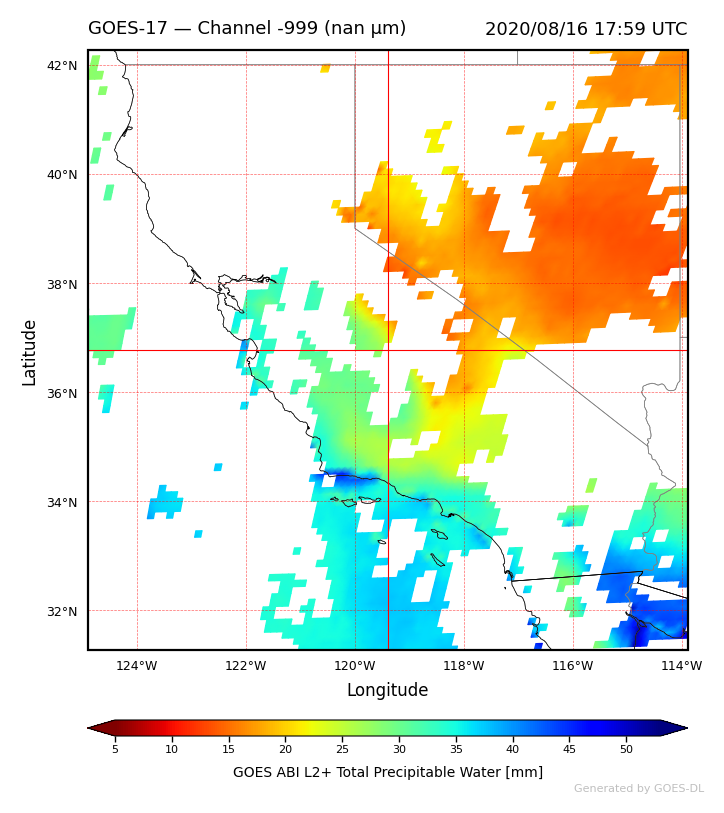


Dataset 7/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291800321_e20202291809388_c20202291810245.nc
-----------------------------------------------------


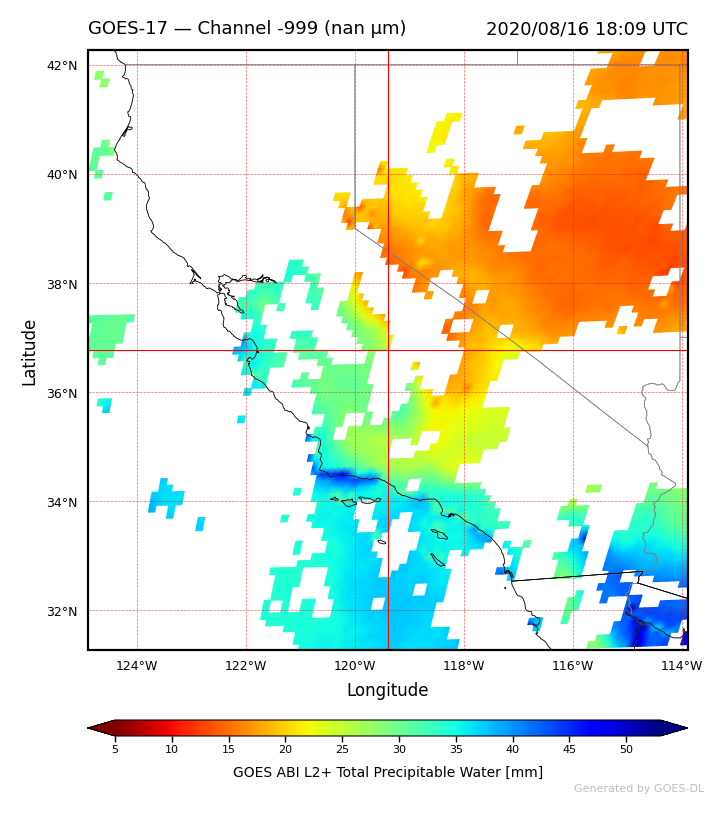


Dataset 8/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291810321_e20202291819388_c20202291820263.nc
-----------------------------------------------------


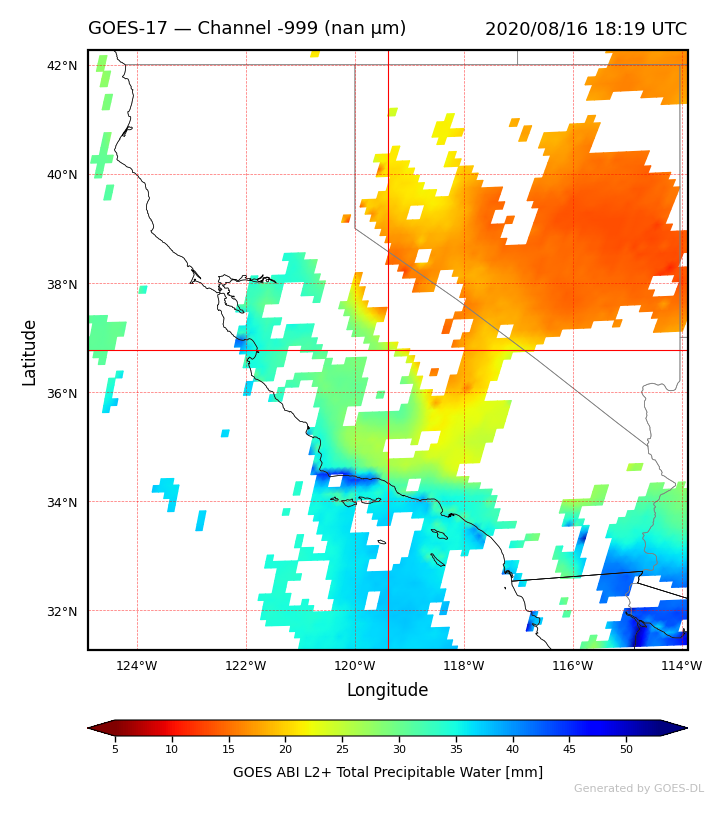


Dataset 9/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291820321_e20202291829388_c20202291830249.nc
-----------------------------------------------------


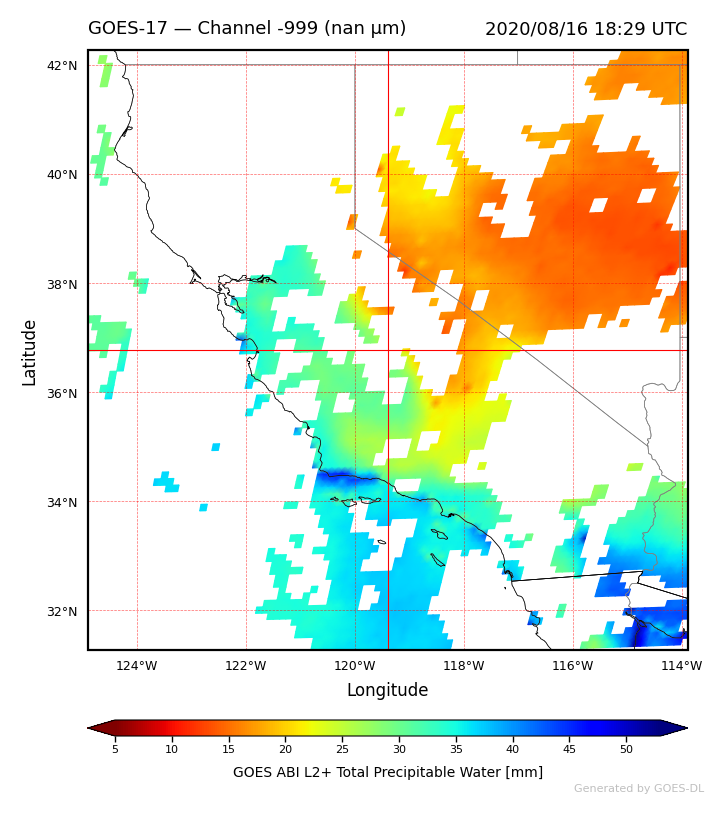


Dataset 10/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291830321_e20202291839388_c20202291840228.nc
-----------------------------------------------------


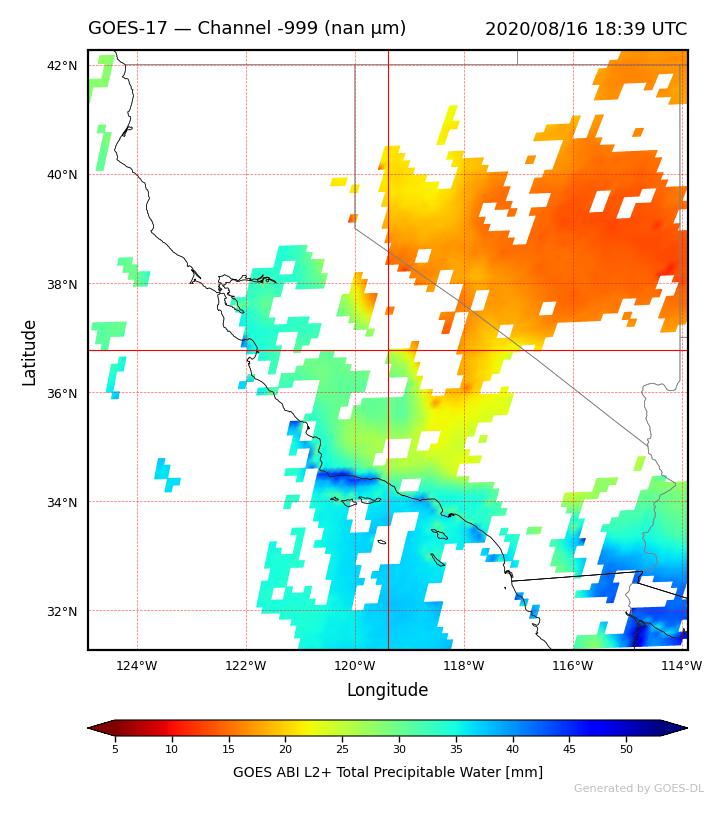


Dataset 11/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291840321_e20202291849388_c20202291850175.nc
-----------------------------------------------------


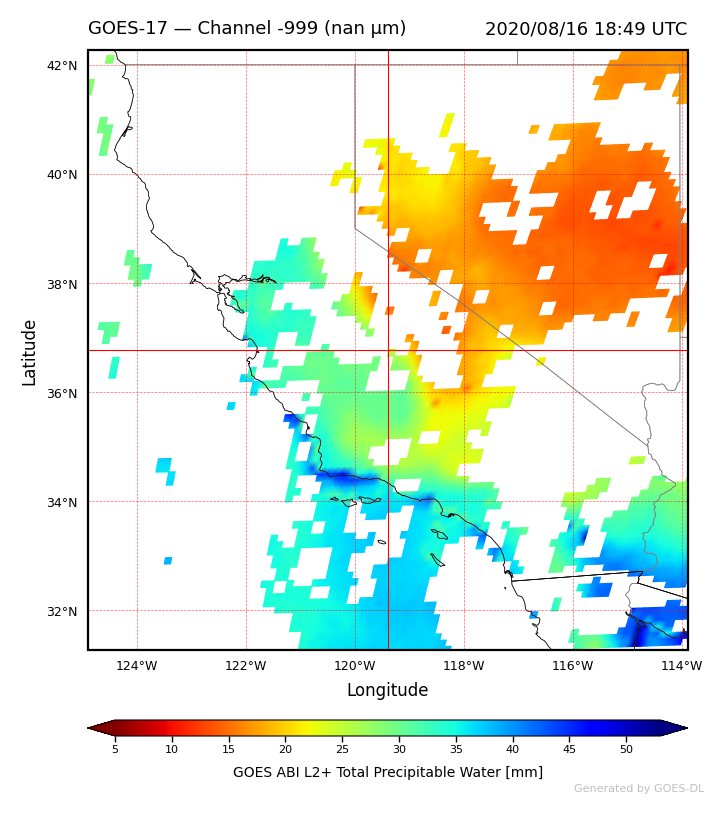


Dataset 12/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291850321_e20202291859388_c20202291900174.nc
-----------------------------------------------------


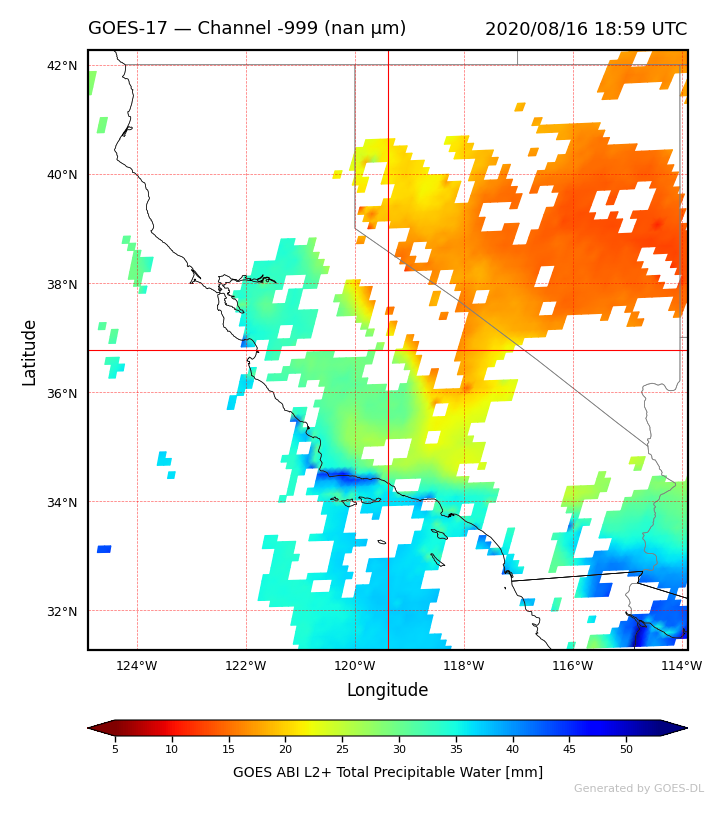


Dataset 13/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291900321_e20202291909388_c20202291910223.nc
-----------------------------------------------------


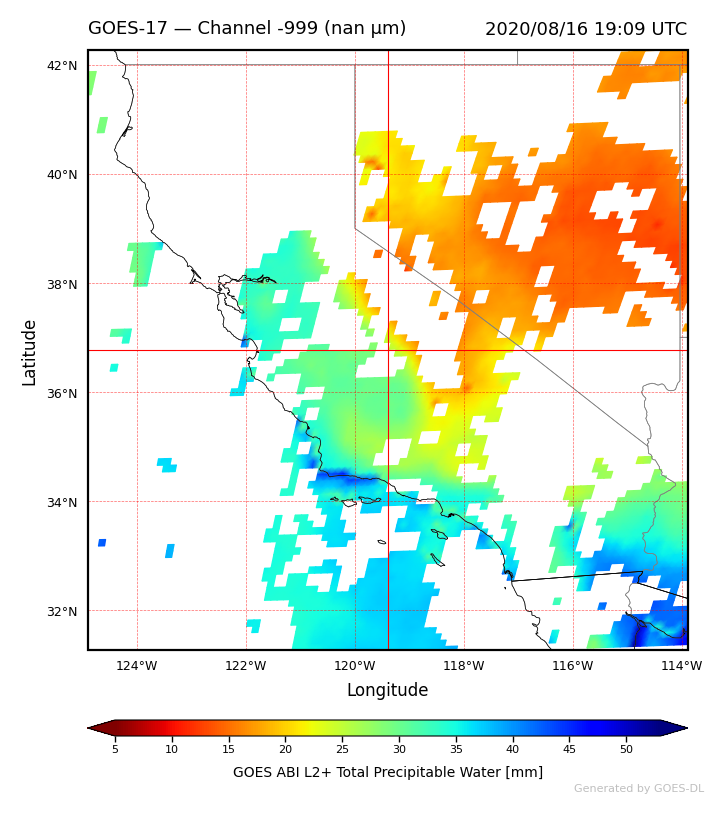


Dataset 14/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291910321_e20202291919388_c20202291920223.nc
-----------------------------------------------------


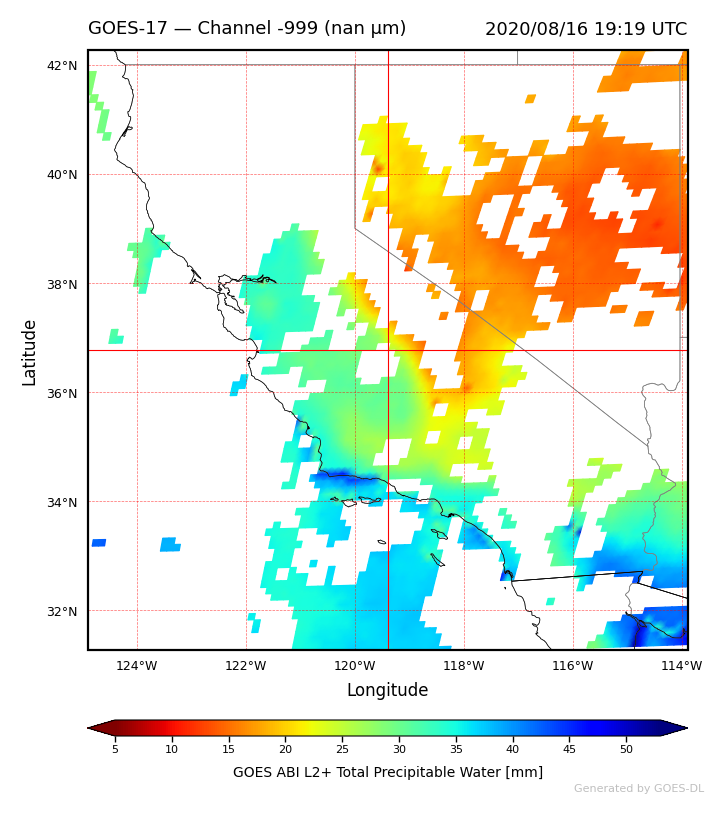


Dataset 15/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291920321_e20202291929388_c20202291930163.nc
-----------------------------------------------------


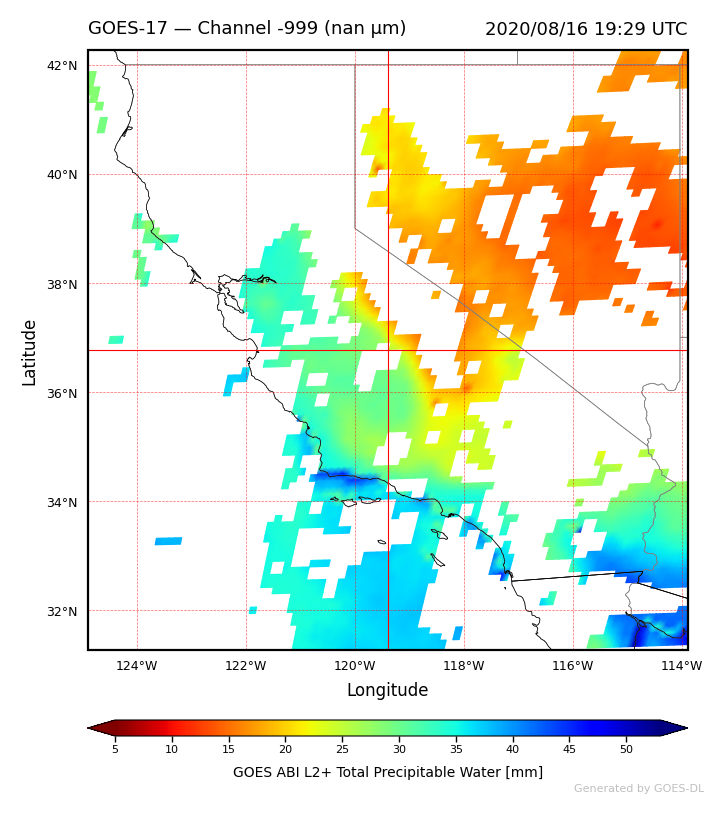


Dataset 16/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291930321_e20202291939388_c20202291940212.nc
-----------------------------------------------------


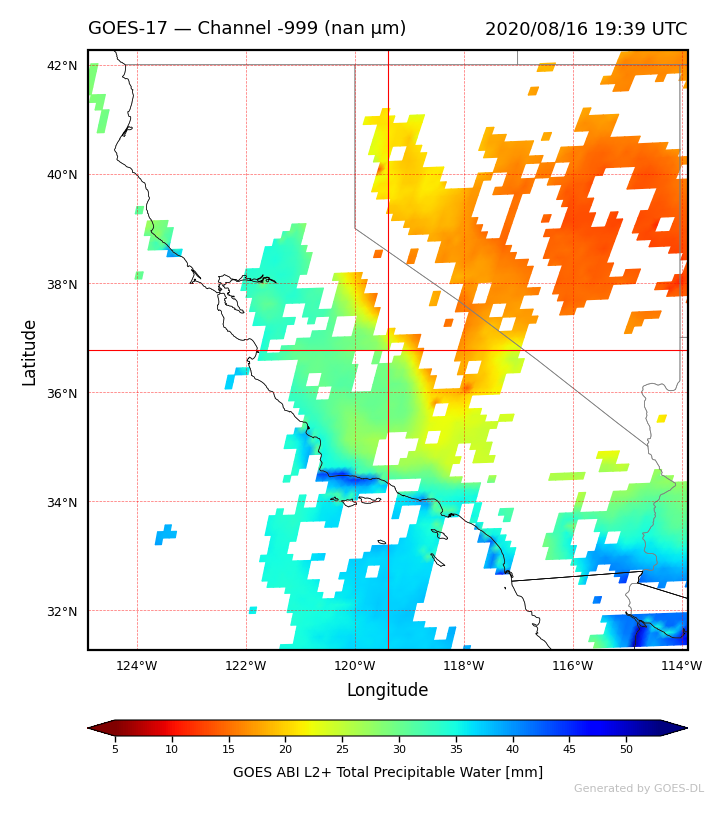


Dataset 17/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291940321_e20202291949388_c20202291950177.nc
-----------------------------------------------------


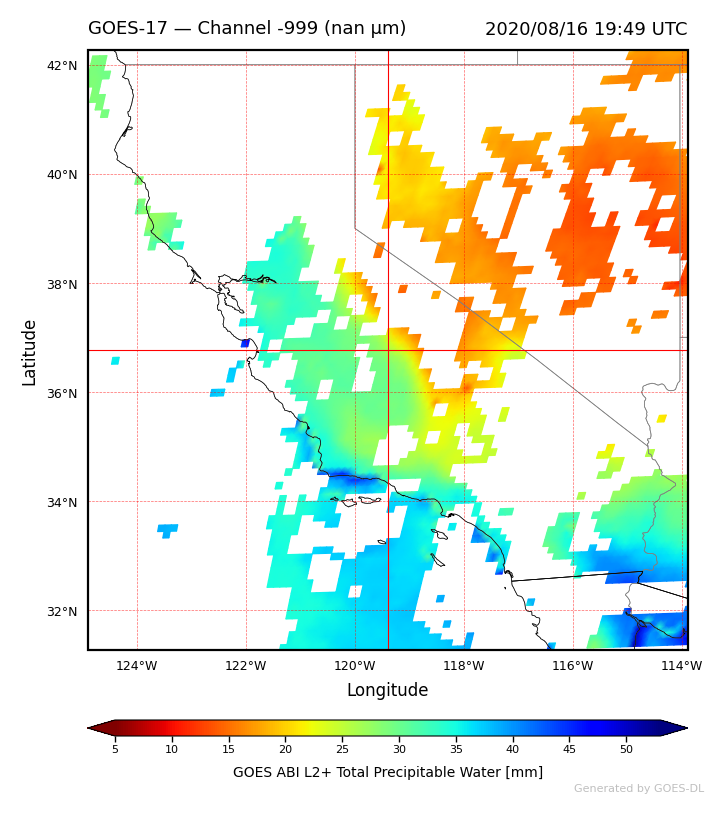


Dataset 18/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202291950321_e20202291959388_c20202292000168.nc
-----------------------------------------------------


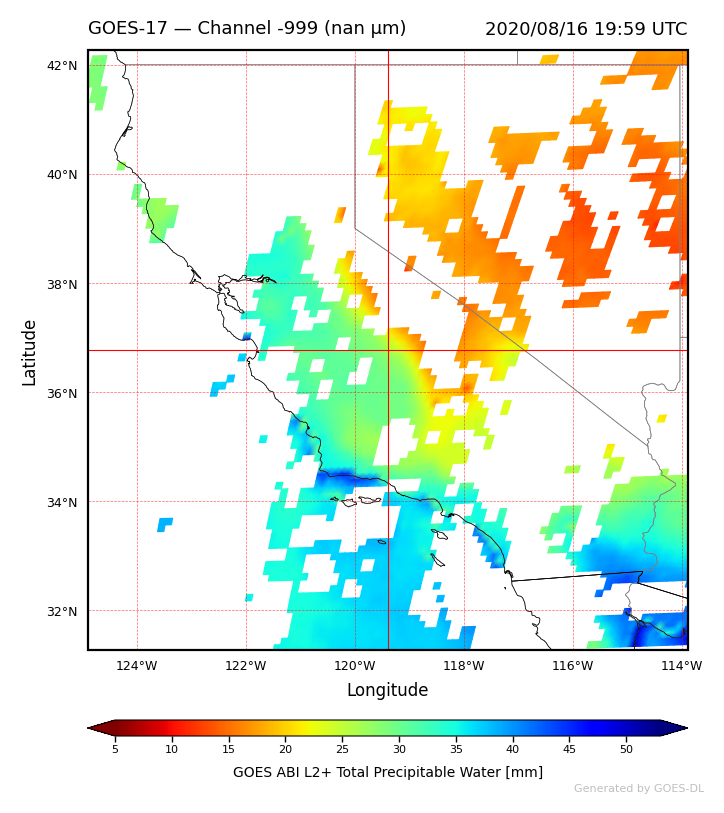


Dataset 19/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292000321_e20202292009388_c20202292010181.nc
-----------------------------------------------------


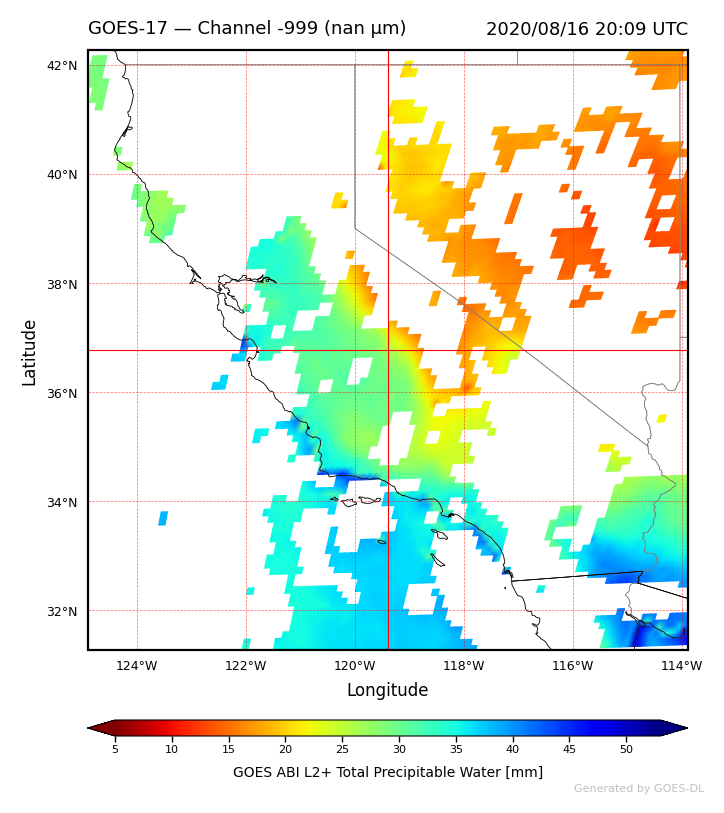


Dataset 20/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292010321_e20202292019388_c20202292020291.nc
-----------------------------------------------------


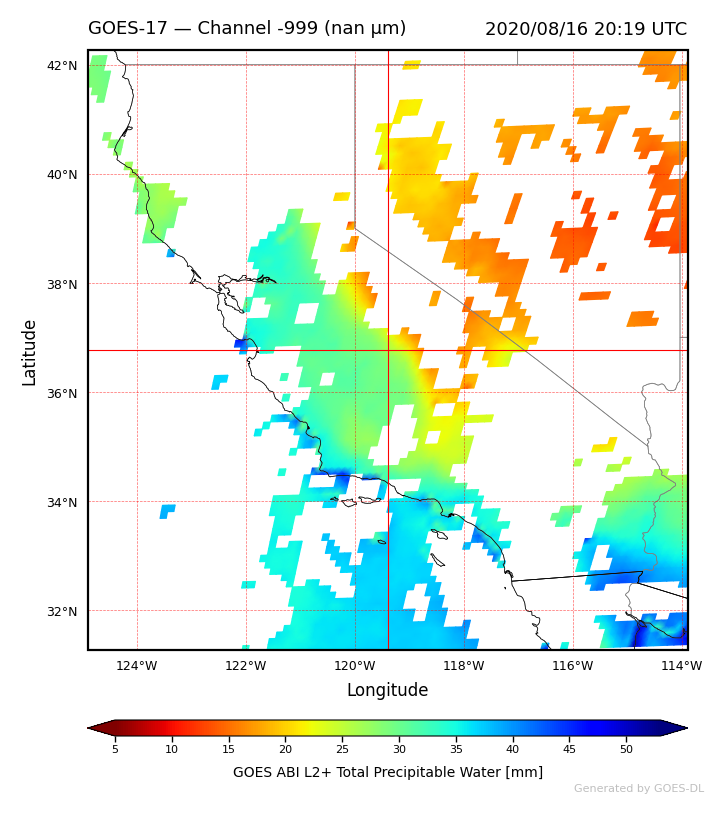


Dataset 21/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292020321_e20202292029388_c20202292030255.nc
-----------------------------------------------------


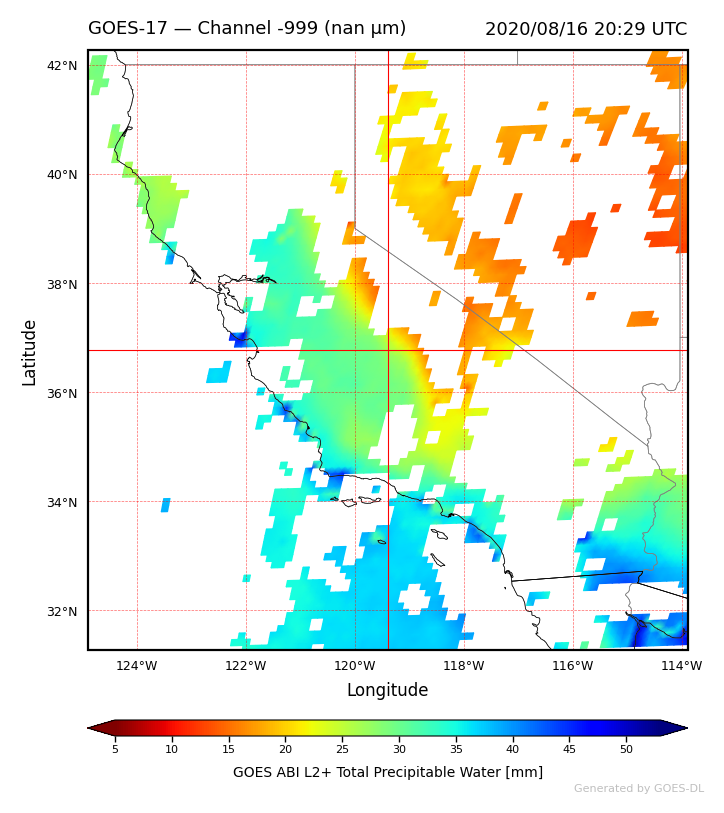


Dataset 22/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292030321_e20202292039388_c20202292040180.nc
-----------------------------------------------------


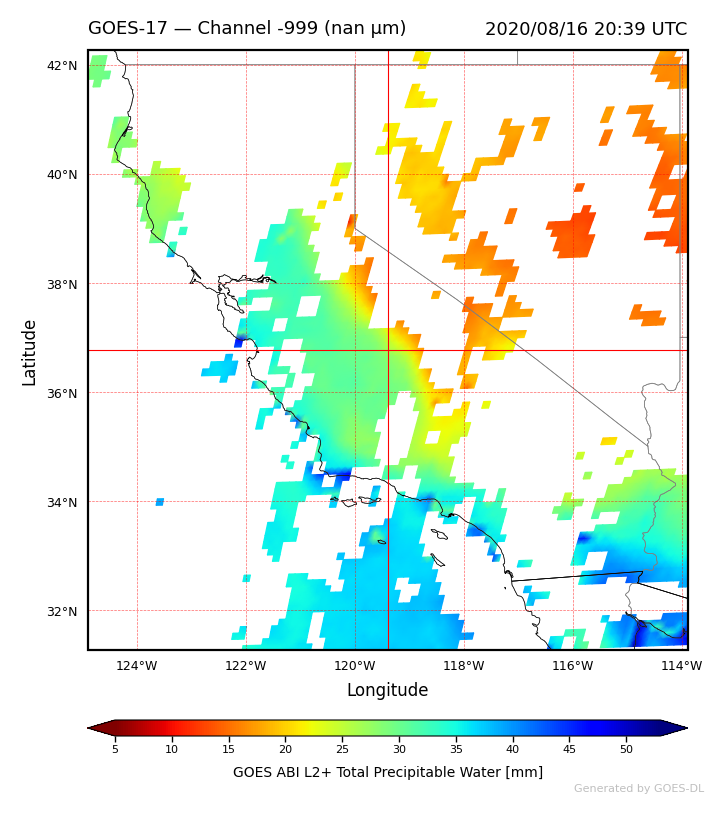


Dataset 23/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292040321_e20202292049388_c20202292050202.nc
-----------------------------------------------------


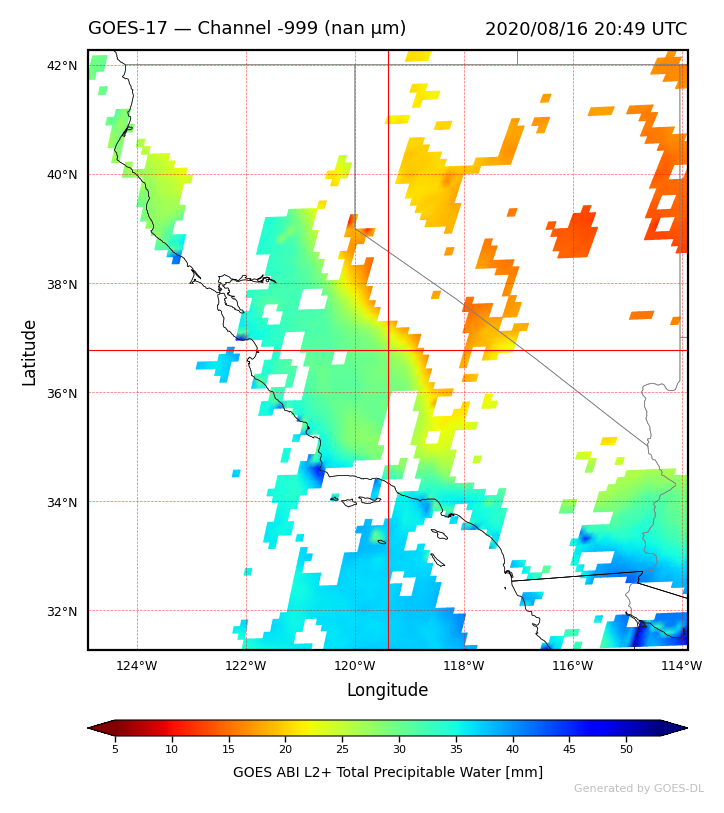


Dataset 24/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292050321_e20202292059388_c20202292100164.nc
-----------------------------------------------------


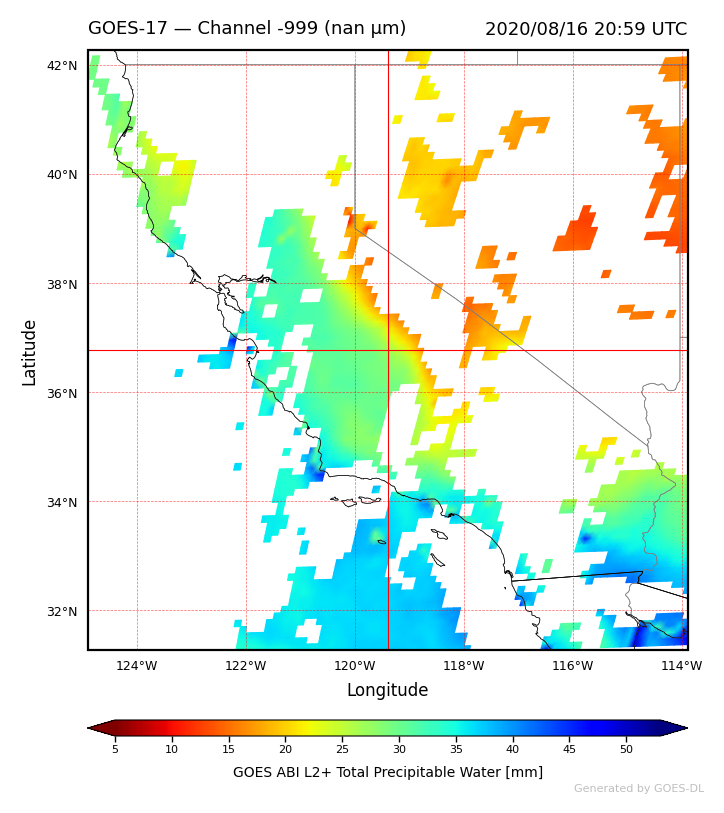


Dataset 25/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292100321_e20202292109388_c20202292110230.nc
-----------------------------------------------------


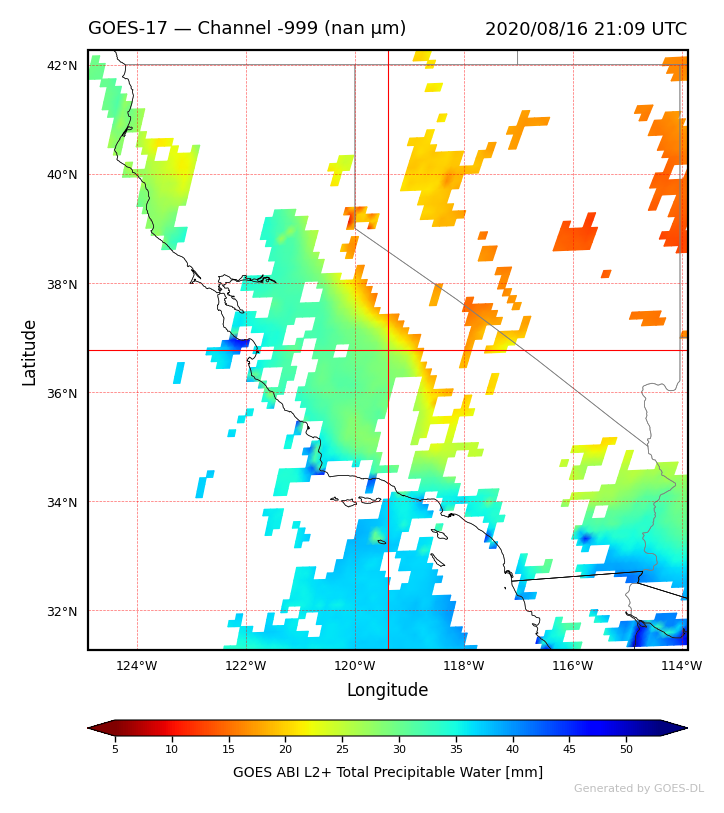


Dataset 26/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292110319_e20202292119385_c20202292120232.nc
-----------------------------------------------------


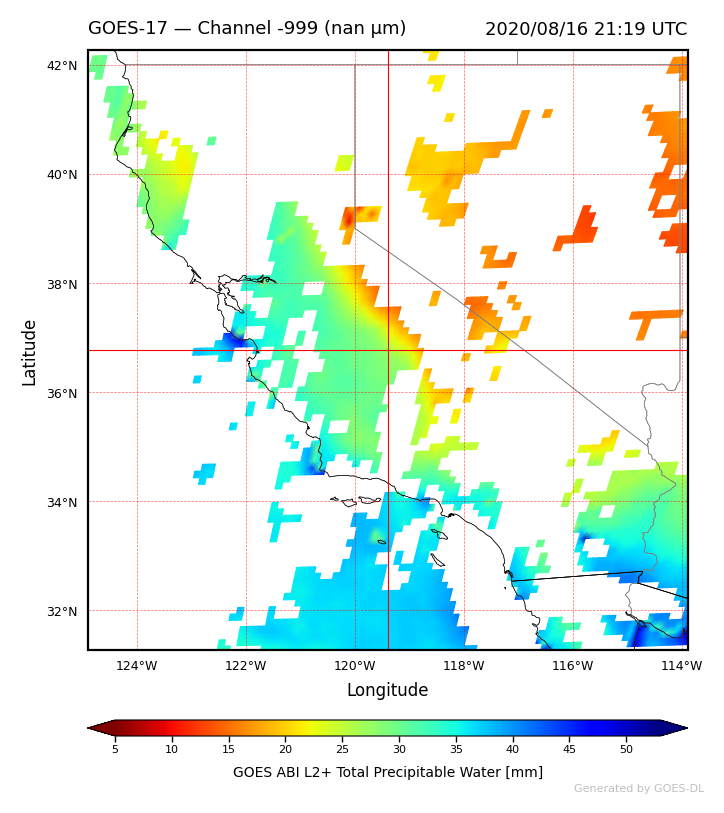


Dataset 27/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292120319_e20202292129385_c20202292130217.nc
-----------------------------------------------------


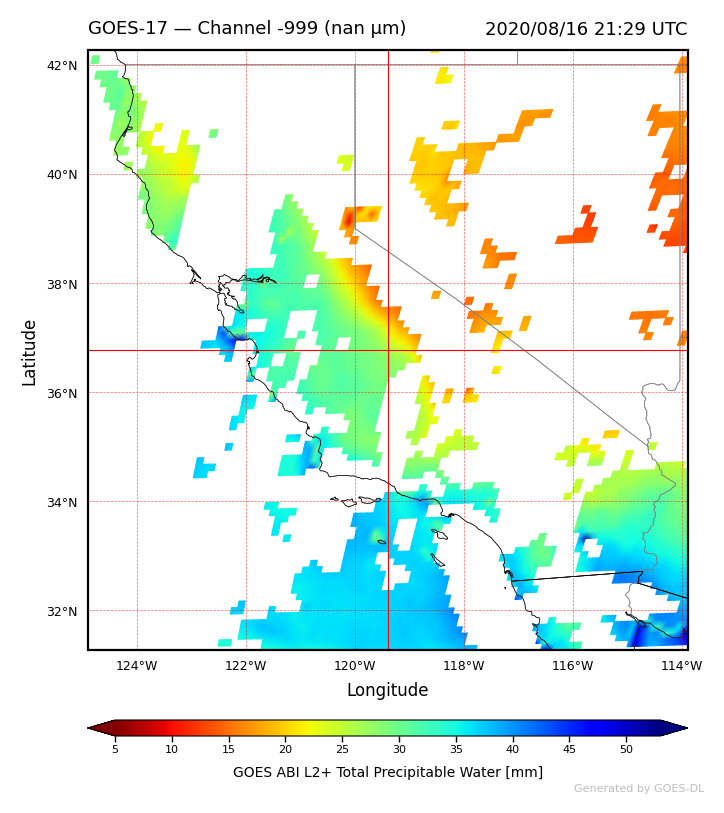


Dataset 28/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292130319_e20202292139385_c20202292140177.nc
-----------------------------------------------------


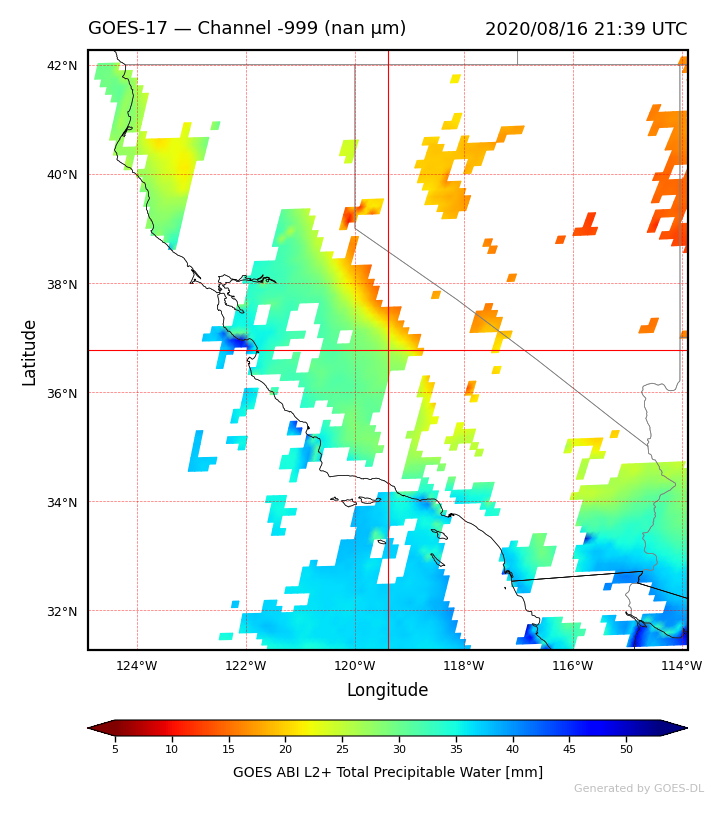


Dataset 29/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292140319_e20202292149385_c20202292150256.nc
-----------------------------------------------------


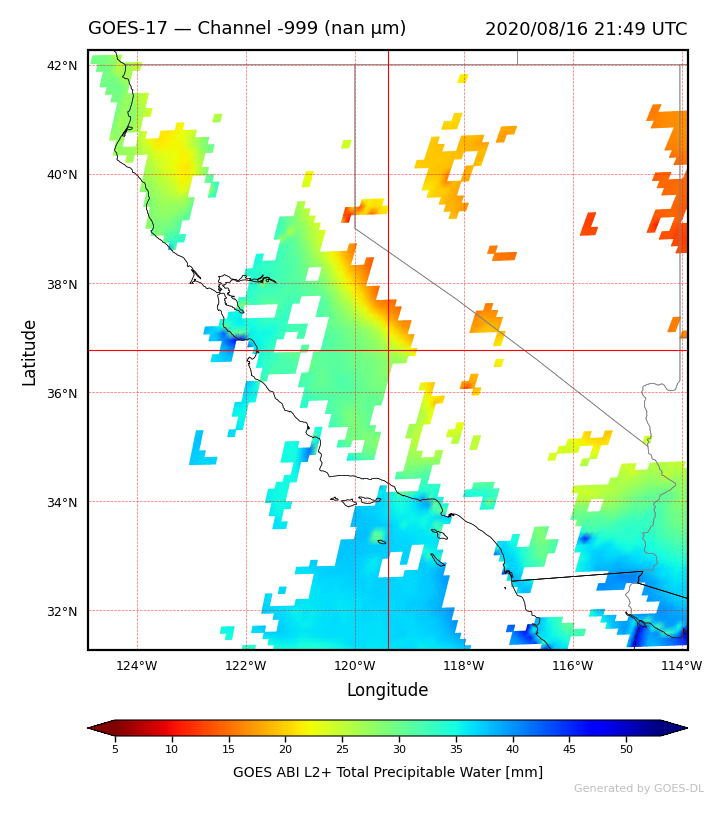


Dataset 30/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292150319_e20202292159385_c20202292200174.nc
-----------------------------------------------------


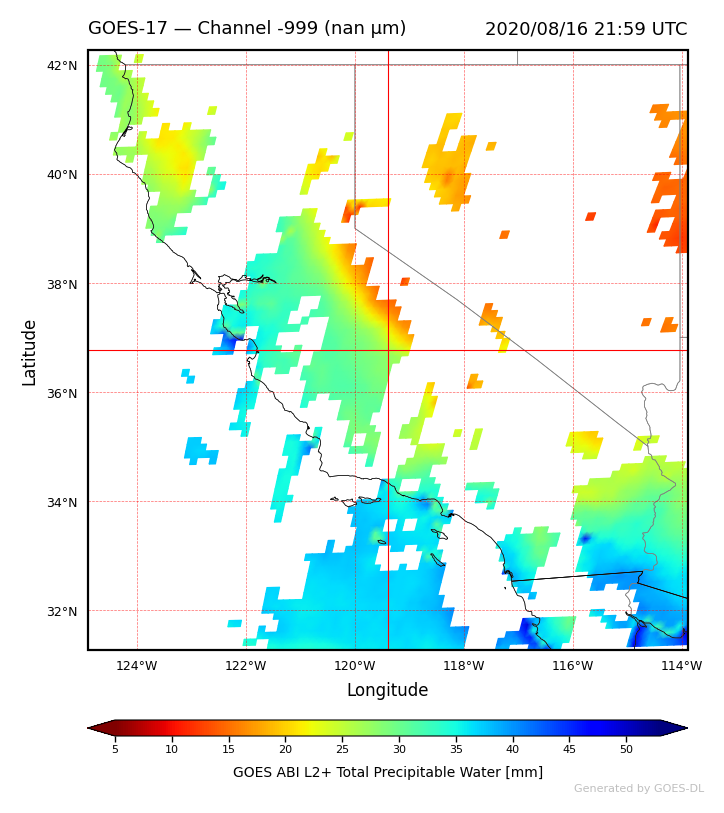


Dataset 31/31
-----------------------------------------------------
Record:    OR_ABI-L2-TPWF-M6_G17_s20202292200319_e20202292209385_c20202292210208.nc
-----------------------------------------------------


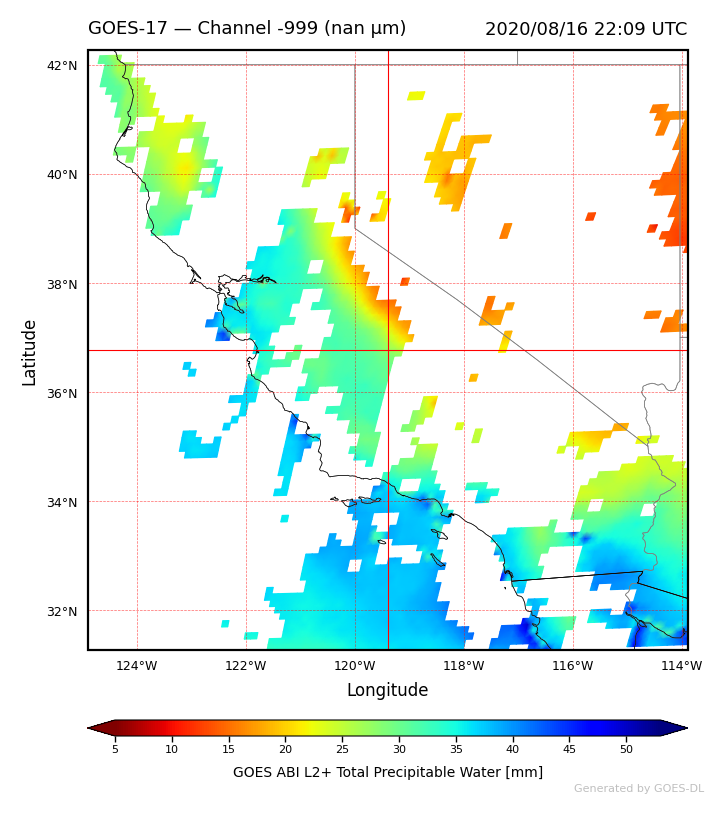

In [74]:
from goesdl.plotting import GSPlot, GSPlotParameter

# Create the basic plotter
plotter = GSPlot()
plotter.enhancement = enhancement
#plotter.enhancement={'cmap': 'grey'}
# Set the plotting projection
plotter.crs = target_crs

# Create list of generated image files (optional)
# Note: this will be used to generate the animation file
media_files = []

# Generate the image files (or visualise)
for i, dataset_path in enumerate(dataset_paths):
    # Get the relevant plotting data
    data = data_seq[i]
    metadata = metadata_seq[i]

    print(f"\nDataset {i + 1}/{len(dataset_paths)}")
    print("-----------------------------------------------------")
    print(f"Record:    {metadata.dataset_name}")
    print("-----------------------------------------------------")

    # Set the title
    title_left = f"{metadata.plaform_name} — Channel {metadata.band_id} ({metadata.band_wavelength:.1f} μm)"
    title_right = f"{metadata.coverage_end:{DATE_FORMAT_FG}}"

    # Set XY-axis label
    x_label = "Longitude"
    y_label = "Latitude"

    # Set the colorbar caption
    # f"{cmi_entity} {cmi_measure} [{cmi_units}]" -> TOA Brightness Temperature
    # cb_label = f"{image.metadata.long_name} @ {metadata.wavelength:.1f} μm [{image.metadata.units}]"
    cb_label = f"{metadata.database_name} {metadata.measurement_name} [{metadata.units}]"

    # Create the plot parameters
    param = GSPlotParameter((title_left, title_right), (x_label, y_label), cb_label)

    # Save the media file (ensure the destination path does exist)
    file_path = MEDIA_PATH/ dataset_path.with_suffix(MEDIA_SUFFIX).name

    # Create the figure and setup the axes

    plotter.plot(data, param, file_path)
    # Add the generate image file path to the media file list
    media_files.append(file_path)

In [40]:
data

## Create the animation file

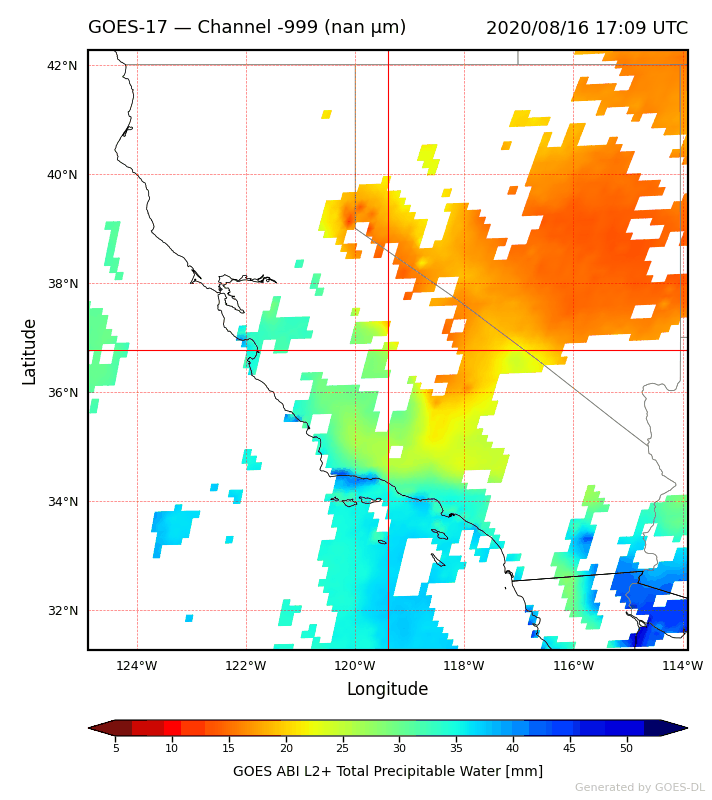

In [75]:
from IPython.display import Image
from goesdl.experimental.animation import create_animation

file_path = MEDIA_PATH / f"{EVENT}{ANIMATION_SUFFIX}"

create_animation(
    media_list=media_files,
    output_path=file_path,
    fps=5,
    loop=True,
)

display(Image(filename=file_path))